# Deep Learning Project 1 — ResNet + SLA + SAM (600 epochs, Cutout after rotation)

Same model and recipe as `DL_Project1_SLA_SAM.ipynb`, with two changes:
* **600 epochs** instead of 200. The one-cycle schedule stretches over the whole run, so the warm-up, the high-LR phase and
  the final decay are all 3× longer.
* **Cutout after the rotations.** Previously each image was augmented once (crop, flip, AutoAugment, Cutout) and then
  copied into its 4 orientations, so all 4 copies shared the same masked square. Now crop, flip and AutoAugment are still
  shared, but Cutout is applied **separately to every rotated copy**, so the 4 copies of an image hide 4 different regions
  in the same step (`cutout_after_rotation` in the Config cell; `False` restores the old order).

Checkpoints and outputs carry the suffix `_cutrot`, so this run never resumes from or overwrites the other runs.

---


The same ResNet as `DL_Project1_ResNet_CIFAR10.ipynb` (C = 80/160/320, B = 2/3/2, ≈4.8M parameters), trained with two
additions:

### 1. SLA — Self-supervised Label Augmentation (Lee, Hwang & Shin, ICML 2020)
Every training image is shown in **4 orientations** (0°, 90°, 180°, 270°), and the network predicts the **joint label**
*(class, rotation)* — 10 × 4 = 40 outputs instead of 10. For example, "cat rotated 90°" is its own label.
* Plain rotation augmentation would *hurt*: a rotated cat would have to be called "cat", which makes the task ambiguous
  (a 180° "6" is a "9"). Predicting the rotation as part of the label removes that ambiguity, and recognising orientation
  forces the network to learn the object's shape and structure — a self-supervised signal on top of the class label.
* **At test time** the image is again fed in all 4 orientations and the matching outputs are combined
  (*aggregation*): for class $c$, average the logit of $(c, 0°)$ on the upright image, $(c, 90°)$ on the 90°-rotated image, and
  so on. Combined with horizontal flips, every test image is predicted from 8 views.
* Cost: the only extra parameters are in the last layer (10 → 40 outputs, +9,630 parameters). Each training step processes
  4× as many images.

### 2. SAM — Sharpness-Aware Minimization (Foret et al., ICLR 2021)
Ordinary SGD looks for weights with low loss. SAM looks for weights whose **whole neighbourhood** has low loss (a *flat*
minimum), which tends to generalise better. Each step:
1. compute the gradient $g$ at the current weights $w$;
2. move to the nearby "worst case" point $w + \rho \, g / \lVert g \rVert$;
3. compute the gradient there, return to $w$, and take the SGD step with that second gradient.

Cost: two forward/backward passes per step. `sam_adaptive=True` switches to ASAM (Kwon et al., 2021), which scales the
neighbourhood by the size of each weight (use a larger `sam_rho`, e.g. 1.0–2.0, with it).

### Compute
SLA (4 orientations) × SAM (2 passes) makes one epoch cost about **8×** an epoch of the earlier notebooks. `rotations` and
`sam` in the Config cell can be switched off independently. Training is resumable (checkpoints every few epochs), which
matters for long runs.

Everything else is the recipe used before: SGD + Nesterov, one-cycle LR peaking at 0.1, weight decay 5e-4, AutoAugment +
Cutout 16, label smoothing 0.1, EMA 0.999, the same stratified 45,000 / 5,000 split (seed 42) for comparability, and
`use_full_train=True` to train on all 50,000 images once the settings are fixed.

**References:** Lee et al. 2020 (Self-supervised Label Augmentation via Input Transformations); Foret et al. 2021
(Sharpness-Aware Minimization for Efficiently Improving Generalization); Kwon et al. 2021 (ASAM); Gidaris et al. 2018
(rotation prediction as self-supervision); Hendrycks et al. 2019 (self-supervision improves robustness); He et al. 2016;
Zagoruyko & Komodakis 2016; Cubuk et al. 2019; DeVries & Taylor 2017.

## 1. Setup

In [1]:
import os, sys, time, math, json, copy, glob, zipfile, shutil, platform, random
from concurrent.futures import ThreadPoolExecutor

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision
from torchvision.transforms import v2

IN_COLAB = "google.colab" in sys.modules
IS_WINDOWS = platform.system() == "Windows"
if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")

assert torch.cuda.is_available(), "A CUDA device is required"
device = torch.device("cuda")
torch.backends.cudnn.benchmark = True
torch.backends.cuda.matmul.allow_tf32 = True
torch.backends.cudnn.allow_tf32 = True

USE_BF16 = torch.cuda.is_bf16_supported()      # otherwise train in fp32 (SAM's two passes make fp16 loss scaling awkward)
props = torch.cuda.get_device_properties(0)
print(f"Python {platform.python_version()} | PyTorch {torch.__version__} | torchvision {torchvision.__version__}")
print(f"GPU: {props.name} | {props.total_memory / 1024**3:.1f} GB | CPU cores: {os.cpu_count()} | Colab: {IN_COLAB}")
print(f"Mixed precision: {'bf16' if USE_BF16 else 'off (fp32)'}")

Mounted at /content/drive
Python 3.13.16 | PyTorch 2.14.1+cu130 | torchvision 0.29.1+cu130
GPU: NVIDIA A100-SXM4-80GB | 79.3 GB | CPU cores: 12 | Colab: True
Mixed precision: bf16


## 2. Config

In [2]:
WORK_DIR = "/content/drive/MyDrive/dl_project1" if IN_COLAB else os.path.abspath(".")

CFG = dict(
    # ---- paths ----
    data_zip   = os.path.join(WORK_DIR, "data.zip"),
    data_dir   = "/content/data" if IN_COLAB else os.path.join(WORK_DIR, "data"),
    cache_file = os.path.join(WORK_DIR, "cifar_kaggle_uint8.npz"),      # shared with the other notebooks
    ckpt_dir   = os.path.join(WORK_DIR, "sla_sam_checkpoints"),
    out_dir    = os.path.join(WORK_DIR, "sla_sam_outputs"),

    # ---- data ----
    val_size = 5000,              # stratified hold-out (500/class), same split as the earlier notebooks
    seed = 42,
    use_full_train = False,       # True = train on all 50,000 images (no validation; the final EMA weights are used)

    # ---- model ----
    model = dict(channels=(80, 160, 320), blocks=(2, 3, 2)),

    # ---- SLA ----
    rotations = (0, 1, 2, 3),     # multiples of 90 degrees; must start with 0. (0,) switches SLA off
    label_smoothing = 0.1,

    # ---- SAM ----
    sam = True,
    sam_rho = 0.05,               # neighbourhood radius (0.05 for SAM; ~1.0-2.0 if sam_adaptive=True)
    sam_adaptive = False,         # True = ASAM

    # ---- optimisation ----
    batch_size = 128,             # original images per step; each appears in every orientation -> 512 inputs per step
    lr = 0.1,
    momentum = 0.9,
    weight_decay = 5e-4,
    pct_start = 0.15,
    ema_decay = 0.999,
    epochs = 600,                 # each epoch costs ~8x an earlier-notebook epoch with SLA + SAM

    # ---- augmentation ----
    cutout = 16,
    cutout_after_rotation = True, # True = a separate Cutout square for every rotated copy; False = one square shared by all 4
    aa_chunk = 16,

    # ---- system ----
    use_compile = not IS_WINDOWS, # torch.compile needs Triton (Linux)
    compile_mode = "default",
    ckpt_every = 5,
    smoke = False,                # True = 2 epochs on a small subset, to test the whole pipeline quickly
)
if CFG["smoke"]:
    CFG.update(epochs=2, ckpt_every=1, ckpt_dir=CFG["ckpt_dir"] + "_smoke", out_dir=CFG["out_dir"] + "_smoke")

ROT = tuple(CFG["rotations"])
NR = len(ROT)
assert ROT[0] == 0, "rotations must start with 0 (the upright image)"
RUN_NAME = f"sla{NR}_{'asam' if CFG['sam_adaptive'] else 'sam'}{CFG['sam_rho'] if CFG['sam'] else 'off'}_e{CFG['epochs']}" \
           + ("_cutrot" if CFG["cutout"] and CFG["cutout_after_rotation"] and NR > 1 else "") \
           + ("_full" if CFG["use_full_train"] else "")
os.makedirs(CFG["ckpt_dir"], exist_ok=True)
os.makedirs(CFG["out_dir"], exist_ok=True)

def seed_everything(seed):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)
seed_everything(CFG["seed"])
print("run:", RUN_NAME)
print(json.dumps({k: (str(v) if isinstance(v, (tuple, dict)) else v) for k, v in CFG.items()}, indent=2))

run: sla4_sam0.05_e600_cutrot
{
  "data_zip": "/content/drive/MyDrive/dl_project1/data.zip",
  "data_dir": "/content/data",
  "cache_file": "/content/drive/MyDrive/dl_project1/cifar_kaggle_uint8.npz",
  "ckpt_dir": "/content/drive/MyDrive/dl_project1/sla_sam_checkpoints",
  "out_dir": "/content/drive/MyDrive/dl_project1/sla_sam_outputs",
  "val_size": 5000,
  "seed": 42,
  "use_full_train": false,
  "model": "{'channels': (80, 160, 320), 'blocks': (2, 3, 2)}",
  "rotations": "(0, 1, 2, 3)",
  "label_smoothing": 0.1,
  "sam": true,
  "sam_rho": 0.05,
  "sam_adaptive": false,
  "batch_size": 128,
  "lr": 0.1,
  "momentum": 0.9,
  "weight_decay": 0.0005,
  "pct_start": 0.15,
  "ema_decay": 0.999,
  "epochs": 600,
  "cutout": 16,
  "cutout_after_rotation": true,
  "aa_chunk": 16,
  "use_compile": true,
  "compile_mode": "default",
  "ckpt_every": 5,
  "smoke": false
}


## 3. Data

In [3]:
CLASSES = ["airplane", "automobile", "bird", "cat", "deer", "dog", "frog", "horse", "ship", "truck"]

def find_file(pattern, root):
    hits = glob.glob(os.path.join(root, "**", pattern), recursive=True)
    return hits[0] if hits else None

def load_pngs(folder, filenames):
    def _load(fn):
        with Image.open(os.path.join(folder, fn)) as im:
            return np.asarray(im.convert("RGB"), dtype=np.uint8)
    with ThreadPoolExecutor(32) as ex:
        return np.stack(list(ex.map(_load, filenames)))

t0 = time.time()
if os.path.exists(CFG["cache_file"]):
    d = np.load(CFG["cache_file"])
    x_all, y_all, x_test, test_ids = d["x_all"], d["y_all"], d["x_test"], d["test_ids"]
    print(f"Loaded cached arrays from {CFG['cache_file']}")
else:
    if find_file("train_labels.csv", CFG["data_dir"]) is None:
        zp = CFG["data_zip"]
        assert os.path.exists(zp), f"Upload the Kaggle data.zip to {zp}"
        if IN_COLAB:                       # extract from a local copy (much faster)
            shutil.copy(zp, "/content/data.zip"); zp = "/content/data.zip"
        print("Extracting", zp)
        with zipfile.ZipFile(zp) as z:
            z.extractall(CFG["data_dir"])
    labels_csv = find_file("train_labels.csv", CFG["data_dir"])
    root = os.path.dirname(labels_csv)
    train_df = pd.read_csv(labels_csv)
    test_df = pd.read_csv(os.path.join(root, "test.csv"))
    x_all = load_pngs(os.path.join(root, "train_images"), train_df["filename"])
    y_all = train_df["label"].to_numpy(dtype=np.int64)
    x_test = load_pngs(os.path.join(root, "test_images"), test_df["filename"])
    test_ids = test_df["id"].to_numpy()
    np.savez(CFG["cache_file"], x_all=x_all, y_all=y_all, x_test=x_test, test_ids=test_ids)
    print(f"Decoded PNGs and cached them to {CFG['cache_file']}")
print(f"{len(x_all)} train + {len(x_test)} test images in {time.time() - t0:.0f}s")

# Same stratified split as the earlier notebooks (seed 42, 500 images per class)
rng = np.random.RandomState(CFG["seed"])
val_idx = np.concatenate([rng.permutation(np.where(y_all == c)[0])[:CFG["val_size"] // 10] for c in range(10)])
train_mask = np.ones(len(y_all), dtype=bool); train_mask[val_idx] = False
if CFG["use_full_train"]:
    x_train, y_train, x_val, y_val = x_all, y_all, None, None
else:
    x_train, y_train = x_all[train_mask], y_all[train_mask]
    x_val, y_val = x_all[val_idx], y_all[val_idx]
if CFG["smoke"]:
    x_train, y_train = x_train[:2048], y_train[:2048]
    if x_val is not None:
        x_val, y_val = x_val[::10], y_val[::10]

def to_gpu_images(x):        # (N, 32, 32, 3) uint8 -> (N, 3, 32, 32) uint8 on the device
    return torch.from_numpy(x).permute(0, 3, 1, 2).contiguous().to(device)

X_train, Y_train = to_gpu_images(x_train), torch.from_numpy(y_train).to(device)
HAS_VAL = x_val is not None
X_val = to_gpu_images(x_val) if HAS_VAL else None
Y_val = torch.from_numpy(y_val).to(device) if HAS_VAL else None
X_test = to_gpu_images(x_test)
print(f"train {tuple(X_train.shape)}, val {tuple(X_val.shape) if HAS_VAL else None}, test {tuple(X_test.shape)}")

Loaded cached arrays from /content/drive/MyDrive/dl_project1/cifar_kaggle_uint8.npz
50000 train + 2000 test images in 9s
train (45000, 3, 32, 32), val (5000, 3, 32, 32), test (2000, 3, 32, 32)


### Augmentation pipeline + SLA rotations
Each batch gets the usual augmentation (random crop with reflect padding 4, horizontal flip, AutoAugment), then
**every augmented image is added in all 4 orientations** with joint label `class × 4 + rotation`, and finally
**Cutout 16 is applied to each of the 4 copies independently**, so every orientation hides a different square.
In the preview below, each row is one image: the masked square should be in a different place in every column.

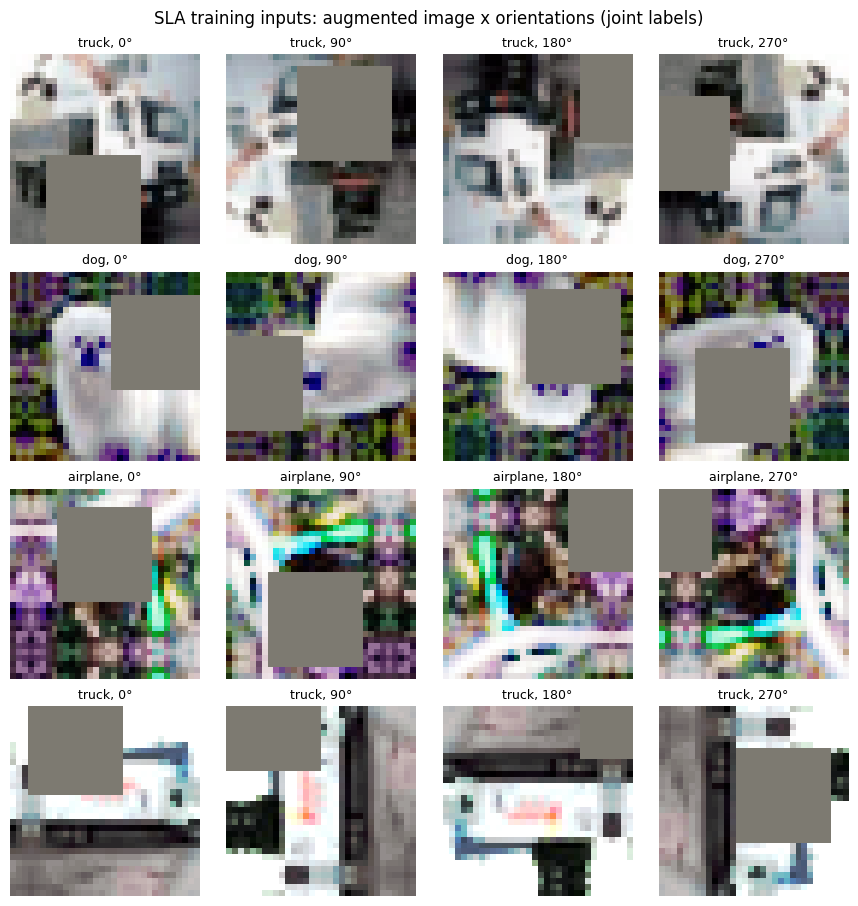

In [4]:
MEAN = torch.tensor([0.4914, 0.4822, 0.4465], device=device).view(1, 3, 1, 1) * 255
STD = torch.tensor([0.2470, 0.2435, 0.2616], device=device).view(1, 3, 1, 1) * 255
AUTO_AUGMENT = v2.AutoAugment(v2.AutoAugmentPolicy.CIFAR10)

def _reflect(i, n):
    i = i.abs()
    return torch.where(i > n - 1, 2 * (n - 1) - i, i)

def random_crop_flip(x, pad=4):
    # Per-image random crop from a reflect-padded image + random horizontal flip, as one gather.
    B, C, H, W = x.shape
    dy = torch.randint(-pad, pad + 1, (B, 1), device=x.device)
    dx = torch.randint(-pad, pad + 1, (B, 1), device=x.device)
    rows = _reflect(torch.arange(H, device=x.device)[None] + dy, H)
    cols = _reflect(torch.arange(W, device=x.device)[None] + dx, W)
    flip = torch.rand(B, 1, device=x.device) < 0.5
    cols = torch.where(flip, cols.flip(1), cols)
    b = torch.arange(B, device=x.device)[:, None, None]
    return x[b, :, rows[:, :, None], cols[:, None, :]].permute(0, 3, 1, 2)

def auto_augment(x):
    # One random AutoAugment sub-policy per chunk of images.
    return torch.cat([AUTO_AUGMENT(c) for c in x.split(CFG["aa_chunk"])])

def cutout(x, size):
    B, _, H, W = x.shape
    cy = torch.randint(0, H, (B, 1, 1), device=x.device)
    cx = torch.randint(0, W, (B, 1, 1), device=x.device)
    ys = torch.arange(H, device=x.device).view(1, H, 1)
    xs = torch.arange(W, device=x.device).view(1, 1, W)
    mask = (ys >= cy - size // 2) & (ys < cy + size // 2) & (xs >= cx - size // 2) & (xs < cx + size // 2)
    return x * (~mask).unsqueeze(1)

def normalize(x_uint8):
    return ((x_uint8.float() - MEAN) / STD).contiguous(memory_format=torch.channels_last)

def augment(x_uint8, with_cutout=True):
    x = auto_augment(random_crop_flip(x_uint8).contiguous())
    x = (x.float() - MEAN) / STD
    if CFG["cutout"] and with_cutout:
        x = cutout(x, CFG["cutout"])
    return x

def rotate(x, k):
    return torch.rot90(x, k, dims=(2, 3)) if k % 4 else x

def sla_expand(x, y):
    # (B images, B labels) -> (NR*B images in every orientation, joint labels class*NR + orientation index)
    xs = torch.cat([rotate(x, k) for k in ROT]).contiguous(memory_format=torch.channels_last)
    ys = torch.cat([y * NR + j for j in range(NR)])
    return xs, ys

def train_batches(batch_size):
    perm = torch.randperm(len(X_train), device=device)
    for i in range(0, len(X_train) - batch_size + 1, batch_size):
        idx = perm[i:i + batch_size]
        if CFG["cutout"] and CFG["cutout_after_rotation"]:
            # crop/flip/AutoAugment shared by the 4 copies; Cutout drawn separately for every copy
            xs, ys = sla_expand(augment(X_train[idx], with_cutout=False), Y_train[idx])
            yield cutout(xs, CFG["cutout"]).contiguous(memory_format=torch.channels_last), ys
        else:
            yield sla_expand(augment(X_train[idx]), Y_train[idx])

# Peek: one augmented image per row, in every orientation, with its joint label
xb, yb = next(train_batches(4))
B = len(yb) // NR
imgs = (xb.float() * STD + MEAN).clamp(0, 255).byte().permute(0, 2, 3, 1).cpu().numpy()
fig, axes = plt.subplots(B, NR, figsize=(2.2 * NR, 2.3 * B), squeeze=False)
for j in range(NR):
    for i in range(B):
        lbl = yb[j * B + i].item()
        axes[i][j].imshow(imgs[j * B + i]); axes[i][j].axis("off")
        axes[i][j].set_title(f"{CLASSES[lbl // NR]}, {ROT[lbl % NR] * 90}°", fontsize=9)
plt.suptitle("SLA training inputs: augmented image x orientations (joint labels)"); plt.tight_layout(); plt.show()

## 4. Model
The same `ResNetCIFAR` as before; the only change is the classifier, which has 10 × (number of orientations) outputs.

In [5]:
class BasicBlock(nn.Module):
    def __init__(self, in_ch, out_ch, stride=1, conv_kernel=3, skip_kernel=1):
        super().__init__()
        p = conv_kernel // 2
        self.conv1 = nn.Conv2d(in_ch, out_ch, conv_kernel, stride, p, bias=False)
        self.bn1 = nn.BatchNorm2d(out_ch)
        self.conv2 = nn.Conv2d(out_ch, out_ch, conv_kernel, 1, p, bias=False)
        self.bn2 = nn.BatchNorm2d(out_ch)
        self.shortcut = nn.Identity()
        if stride != 1 or in_ch != out_ch:
            self.shortcut = nn.Sequential(
                nn.Conv2d(in_ch, out_ch, skip_kernel, stride, skip_kernel // 2, bias=False),
                nn.BatchNorm2d(out_ch))

    def forward(self, x):
        out = F.relu(self.bn1(self.conv1(x)), inplace=True)
        out = self.bn2(self.conv2(out))
        return F.relu(out + self.shortcut(x), inplace=True)


class ResNetCIFAR(nn.Module):
    def __init__(self, channels=(80, 160, 320), blocks=(2, 3, 2), conv_kernel=3, skip_kernel=1, num_classes=10):
        super().__init__()
        self.stem = nn.Sequential(nn.Conv2d(3, channels[0], 3, 1, 1, bias=False),
                                  nn.BatchNorm2d(channels[0]), nn.ReLU(inplace=True))
        layers, in_ch = [], channels[0]
        for i, (ch, n) in enumerate(zip(channels, blocks)):
            for j in range(n):
                stride = 2 if (i > 0 and j == 0) else 1
                layers.append(BasicBlock(in_ch, ch, stride, conv_kernel, skip_kernel))
                in_ch = ch
        self.layers = nn.Sequential(*layers)
        self.pool = nn.AdaptiveAvgPool2d(1)
        self.fc = nn.Linear(in_ch, num_classes)
        self._init_weights()

    def _init_weights(self):
        for m in self.modules():
            if isinstance(m, nn.Conv2d):
                nn.init.kaiming_normal_(m.weight, mode="fan_out", nonlinearity="relu")
            elif isinstance(m, nn.BatchNorm2d):
                nn.init.ones_(m.weight); nn.init.zeros_(m.bias)
        for m in self.modules():
            if isinstance(m, BasicBlock):
                nn.init.zeros_(m.bn2.weight)         # zero-init residual branch

    def forward(self, x):
        x = self.layers(self.stem(x))
        return self.fc(torch.flatten(self.pool(x), 1))


def n_params(model):
    return sum(p.numel() for p in model.parameters())

seed_everything(CFG["seed"])
model = ResNetCIFAR(CFG["model"]["channels"], CFG["model"]["blocks"], num_classes=10 * NR)
model = model.to(device).to(memory_format=torch.channels_last)
P_MODEL = n_params(model)
print(f"ResNet C={CFG['model']['channels']} B={CFG['model']['blocks']} | outputs {10 * NR} (10 classes x {NR} orientations) "
      f"| {P_MODEL:,} parameters")
assert P_MODEL <= 5_000_000, "Model exceeds the 5M parameter limit!"

ResNet C=(80, 160, 320) B=(2, 3, 2) | outputs 40 (10 classes x 4 orientations) | 4,808,440 parameters


## 5. Training utilities
**SAM step** (Foret et al. 2021): perturb the weights by $e = \rho\, g / \lVert g \rVert$ (ASAM: $e = \rho\, |w|^2 g / \lVert |w| g \rVert$),
recompute the gradient at $w + e$, undo the perturbation and let SGD step with the new gradient.

**Inference with SLA aggregation:** for each orientation $k$, take the logits of the joint labels $(c, k)$ on the image rotated
by $k$; average over orientations (and horizontal flips) and apply softmax over the 10 classes. "Single" inference uses only
the upright image's $(c, 0°)$ logits.

In [6]:
def autocast():
    return torch.autocast(device_type="cuda", dtype=torch.bfloat16, enabled=USE_BF16)


class EMA:
    # Exponential moving average of weights and BN statistics.
    def __init__(self, model, decay):
        self.module = copy.deepcopy(model).eval()
        for p in self.module.parameters():
            p.requires_grad_(False)
        self.decay = decay

    @torch.no_grad()
    def update(self, model, step):
        w = 1 - min(self.decay, (1 + step) / (10 + step))
        torch._foreach_lerp_(list(self.module.parameters()), list(model.parameters()), w)
        for eb, mb in zip(self.module.buffers(), model.buffers()):
            if eb.dtype.is_floating_point:
                eb.lerp_(mb, w)
            else:
                eb.copy_(mb)


class SAM:
    """Sharpness-Aware Minimization around a base optimizer (here SGD + Nesterov)."""
    def __init__(self, base_optimizer, rho, adaptive=False):
        self.base, self.rho, self.adaptive = base_optimizer, rho, adaptive
        self.params = [p for g in base_optimizer.param_groups for p in g["params"]]
        self._perturbed, self._e = [], []

    @torch.no_grad()
    def first_step(self):
        ps = [p for p in self.params if p.grad is not None]
        gs = [(p.abs() * p.grad) if self.adaptive else p.grad for p in ps]
        norm = torch.linalg.vector_norm(torch.stack(torch._foreach_norm(gs)))
        scale = self.rho / (norm + 1e-12)
        self._e = [(p.abs() * g * scale) if self.adaptive else (g * scale) for p, g in zip(ps, gs)]
        torch._foreach_add_(ps, self._e)                      # w -> w + e
        self._perturbed = ps

    @torch.no_grad()
    def second_step(self):
        torch._foreach_sub_(self._perturbed, self._e)         # back to w
        self.base.step()                                      # SGD step with the gradient taken at w + e
        self._perturbed, self._e = [], []


def make_optimizer(model, total_steps):
    decay, no_decay = [], []
    for p in model.parameters():
        (no_decay if p.ndim <= 1 else decay).append(p)      # no weight decay on BN parameters / biases
    groups = [{"params": decay, "weight_decay": CFG["weight_decay"]}, {"params": no_decay, "weight_decay": 0.0}]
    kw = dict(lr=CFG["lr"], momentum=CFG["momentum"], nesterov=True)
    try:
        base = torch.optim.SGD(groups, fused=True, **kw)
    except (TypeError, RuntimeError):
        base = torch.optim.SGD(groups, foreach=True, **kw)
    sched = torch.optim.lr_scheduler.OneCycleLR(
        base, max_lr=CFG["lr"], total_steps=total_steps, pct_start=CFG["pct_start"],
        anneal_strategy="cos", div_factor=25.0, final_div_factor=1e4)
    sam = SAM(base, CFG["sam_rho"], CFG["sam_adaptive"]) if CFG["sam"] else None
    return base, sam, sched


@torch.no_grad()
def predict_logits(model, X, aggregate=True, flip=True, bs=500):
    """10-class logits. aggregate=True averages the matching joint logits over all orientations; flip adds mirrored views."""
    model.eval()
    js = range(NR) if aggregate else [0]
    out = []
    for i in range(0, len(X), bs):
        x = normalize(X[i:i + bs])
        views = [x, torch.flip(x, dims=[3])] if flip else [x]
        acc = 0
        for v in views:
            for j in js:
                with autocast():
                    z = model(rotate(v, ROT[j]).contiguous(memory_format=torch.channels_last)).float()
                acc = acc + z.view(len(x), 10, NR)[:, :, j]
        out.append(acc / (len(views) * len(js)))
    return torch.cat(out)


@torch.no_grad()
def evaluate(model, X, Y, aggregate=False, flip=False):
    logits = predict_logits(model, X, aggregate, flip)
    nll = F.cross_entropy(logits, Y).item()
    acc = (logits.argmax(1) == Y).float().mean().item() * 100
    return nll, acc, logits

In [7]:
def train(model, epochs):
    """Train with SLA (+ SAM). Resumable; skipped if already finished. Returns the best (or final EMA) model and info."""
    last_path = os.path.join(CFG["ckpt_dir"], f"{RUN_NAME}_last.pt")
    best_path = os.path.join(CFG["ckpt_dir"], f"{RUN_NAME}_best.pt")
    done_path = os.path.join(CFG["ckpt_dir"], f"{RUN_NAME}_done.json")

    if os.path.exists(done_path):
        info = json.load(open(done_path))
        model.load_state_dict(torch.load(best_path, map_location=device)["model"])
        print(f"[{RUN_NAME}] already trained - loaded checkpoint (epoch {info['best_epoch']}, val {info['best_acc']})")
        return model, info

    steps_per_epoch = len(X_train) // CFG["batch_size"]
    base, sam, sched = make_optimizer(model, epochs * steps_per_epoch)
    ema = EMA(model, CFG["ema_decay"])
    start_epoch, step, best_acc, best_epoch, best_is_ema, history = 0, 0, 0.0, 0, False, []

    if os.path.exists(last_path):
        ck = torch.load(last_path, map_location=device, weights_only=False)
        model.load_state_dict(ck["model"]); ema.module.load_state_dict(ck["ema"])
        base.load_state_dict(ck["opt"]); sched.load_state_dict(ck["sched"])
        start_epoch, step, history = ck["epoch"], ck["step"], ck["history"]
        best_acc, best_epoch, best_is_ema = ck["best_acc"], ck["best_epoch"], ck["best_is_ema"]
        torch.set_rng_state(ck["rng_cpu"]); torch.cuda.set_rng_state(ck["rng_cuda"])
        print(f"[{RUN_NAME}] resumed at epoch {start_epoch}/{epochs} (best val so far {best_acc:.2f}%)")

    fwd = torch.compile(model, mode=CFG["compile_mode"]) if CFG["use_compile"] else model
    ls = CFG["label_smoothing"]
    print(f"[{RUN_NAME}] {n_params(model):,} params | {epochs} epochs x {steps_per_epoch} steps | "
          f"{CFG['batch_size']} images x {NR} orientations per step | "
          + (f"{'ASAM' if CFG['sam_adaptive'] else 'SAM'} rho={CFG['sam_rho']}" if sam else "plain SGD")
          + (" | compiling (first epoch is slower)" if CFG["use_compile"] and start_epoch == 0 else ""))

    for epoch in range(start_epoch, epochs):
        model.train()
        t0 = time.time()
        loss_sum = torch.zeros((), device=device); correct = torch.zeros((), device=device); seen = 0
        for x, y in train_batches(CFG["batch_size"]):
            with autocast():
                out = fwd(x)
                loss = F.cross_entropy(out.float(), y, label_smoothing=ls)
            base.zero_grad(set_to_none=True)
            loss.backward()
            if sam is not None:
                sam.first_step()
                base.zero_grad(set_to_none=True)
                with autocast():
                    loss2 = F.cross_entropy(fwd(x).float(), y, label_smoothing=ls)
                loss2.backward()
                sam.second_step()
            else:
                base.step()
            sched.step()
            ema.update(model, step); step += 1
            loss_sum += loss.detach() * x.size(0); correct += (out.argmax(1) == y).sum(); seen += x.size(0)
        epoch_time = time.time() - t0

        rec = dict(epoch=epoch + 1, lr=base.param_groups[0]["lr"], train_loss=loss_sum.item() / seen,
                   train_acc_joint=correct.item() / seen * 100, time=epoch_time)
        if HAS_VAL:
            val_loss, val_acc, _ = evaluate(model, X_val, Y_val)
            ema_loss, ema_acc, _ = evaluate(ema.module, X_val, Y_val)
            rec.update(val_loss=val_loss, val_acc=val_acc, ema_val_loss=ema_loss, ema_val_acc=ema_acc)
            if max(val_acc, ema_acc) > best_acc:
                best_acc, best_epoch, best_is_ema = max(val_acc, ema_acc), epoch + 1, ema_acc >= val_acc
                torch.save({"model": (ema.module if best_is_ema else model).state_dict(), "is_ema": best_is_ema,
                            "epoch": best_epoch, "val_acc": best_acc}, best_path)
        history.append(rec)
        if (epoch + 1) % CFG["ckpt_every"] == 0 or epoch + 1 == epochs:
            torch.save({"model": model.state_dict(), "ema": ema.module.state_dict(), "opt": base.state_dict(),
                        "sched": sched.state_dict(), "epoch": epoch + 1, "step": step, "history": history,
                        "best_acc": best_acc, "best_epoch": best_epoch, "best_is_ema": best_is_ema,
                        "rng_cpu": torch.get_rng_state(), "rng_cuda": torch.cuda.get_rng_state()}, last_path)

        recent = [h["time"] for h in history[-5:]]
        eta_min = (epochs - epoch - 1) * (sum(recent) / len(recent)) / 60
        msg = (f"[{RUN_NAME}] ep {epoch + 1:3d}/{epochs} | lr {rec['lr']:.2e} | train loss {rec['train_loss']:.3f} "
               f"joint acc {rec['train_acc_joint']:5.2f}%")
        if HAS_VAL:
            msg += (f" | val loss {rec['val_loss']:.3f} acc {rec['val_acc']:5.2f}% | EMA val loss {rec['ema_val_loss']:.3f} "
                    f"acc {rec['ema_val_acc']:5.2f}% | best {best_acc:5.2f}%")
        print(msg + f" | {epoch_time:.0f}s | ETA {eta_min:.0f} min")

    if not HAS_VAL:                                  # no validation: keep the final EMA weights
        best_epoch, best_is_ema, best_acc = epochs, True, None
        torch.save({"model": ema.module.state_dict(), "is_ema": True, "epoch": epochs, "val_acc": None}, best_path)
    info = dict(run=RUN_NAME, params=n_params(model), epochs=epochs, best_acc=best_acc, best_epoch=best_epoch,
                best_is_ema=best_is_ema, train_minutes=sum(h["time"] for h in history) / 60, history=history)
    json.dump(info, open(done_path, "w"))
    pd.DataFrame(history).to_csv(os.path.join(CFG["out_dir"], f"{RUN_NAME}_history.csv"), index=False)
    model.load_state_dict(torch.load(best_path, map_location=device)["model"])
    print(f"[{RUN_NAME}] done in {info['train_minutes']:.1f} min - "
          + (f"best val {best_acc:.2f}% (single view) at epoch {best_epoch} ({'EMA' if best_is_ema else 'raw'} weights)"
             if HAS_VAL else "final EMA weights kept"))
    del base, sam, sched, ema, fwd
    torch.cuda.empty_cache()
    return model, info

## 6. Train

In [8]:
model, info = train(model, CFG["epochs"])

[sla4_sam0.05_e600_cutrot] already trained - loaded checkpoint (epoch 578, val 97.7400004863739)


## 7. Results
Validation accuracy of the selected weights with the four inference modes. "Aggregated + flip" (8 views) is what the
submission uses.

,val loss (NLL),val acc %
inference,,
single view,0.1043,97.76
single + flip,0.0960,97.88
aggregated (4 orientations),0.0907,98.02
aggregated + flip (8 views),0.0890,98.04


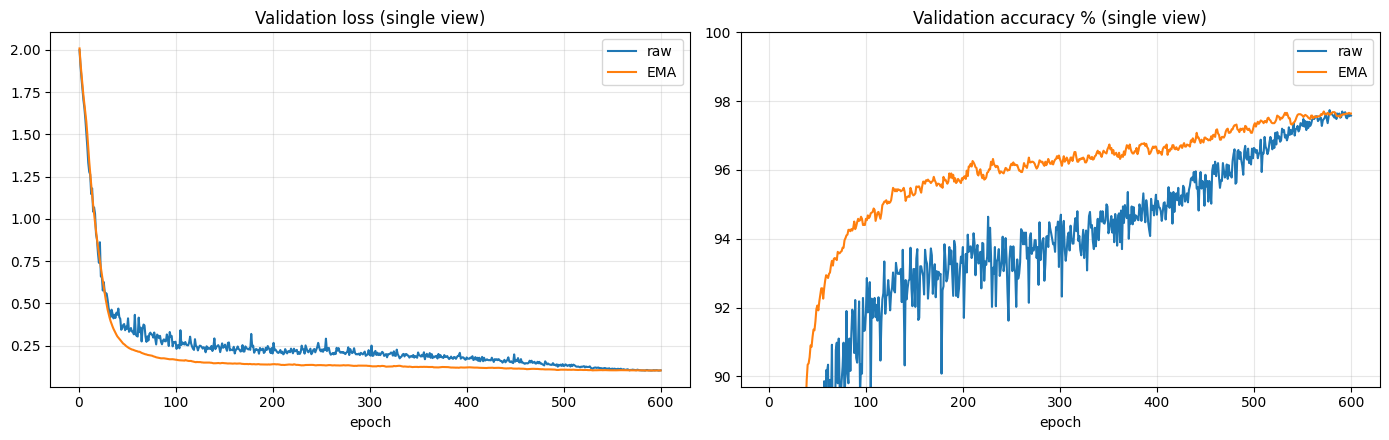

In [9]:
if HAS_VAL:
    rows = []
    for label, agg, flip in [("single view", False, False), ("single + flip", False, True),
                             ("aggregated (4 orientations)", True, False), ("aggregated + flip (8 views)", True, True)]:
        if agg and NR == 1:
            continue
        nll, acc, _ = evaluate(model, X_val, Y_val, aggregate=agg, flip=flip)
        rows.append({"inference": label, "val loss (NLL)": round(nll, 4), "val acc %": round(acc, 2)})
    results = pd.DataFrame(rows).set_index("inference")
    results.to_csv(os.path.join(CFG["out_dir"], f"{RUN_NAME}_results.csv"))
    display(results)

    h = pd.DataFrame(info["history"])
    fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
    ax[0].plot(h.epoch, h.val_loss, label="raw"); ax[0].plot(h.epoch, h.ema_val_loss, label="EMA")
    ax[1].plot(h.epoch, h.val_acc, label="raw"); ax[1].plot(h.epoch, h.ema_val_acc, label="EMA")
    ax[0].set_title("Validation loss (single view)"); ax[1].set_title("Validation accuracy % (single view)")
    ax[1].set_ylim(max(h.ema_val_acc.max() - 8, 0), 100)
    for a in ax:
        a.set_xlabel("epoch"); a.grid(alpha=.3); a.legend()
    plt.tight_layout(); plt.savefig(os.path.join(CFG["out_dir"], f"{RUN_NAME}_curves.png"), dpi=150); plt.show()
else:
    print("Trained on all 50,000 images - no validation set to report.")

## 8. Kaggle submission
`submission_{run}.csv` uses aggregated + flip inference (8 views per image); `submission_{run}_single.csv` uses only the
upright image + its flip, for comparison.

In [10]:
test_logits = predict_logits(model, X_test, aggregate=NR > 1, flip=True)
np.save(os.path.join(CFG["out_dir"], f"test_logits_{RUN_NAME}.npy"), test_logits.cpu().numpy())
for suffix, logits in [("", test_logits), ("_single", predict_logits(model, X_test, aggregate=False, flip=True))]:
    labels = logits.argmax(1).cpu().numpy()
    path = os.path.join(CFG["out_dir"], f"submission_{RUN_NAME}{suffix}.csv")
    pd.DataFrame({"id": test_ids, "label": labels}).to_csv(path, index=False)
    print(f"Wrote {path} | predicted class counts {np.bincount(labels, minlength=10).tolist()}")

summary = {
    "run": RUN_NAME,
    "architecture": f"ResNet, N=3, C={CFG['model']['channels']}, B={CFG['model']['blocks']}, F=3, K=1, global avg pool, "
                    f"{10 * NR}-way joint (class x orientation) classifier",
    "params": P_MODEL,
    "sla_rotations_deg": [k * 90 for k in ROT],
    "sam": {"on": CFG["sam"], "rho": CFG["sam_rho"], "adaptive": CFG["sam_adaptive"]},
    "epochs": CFG["epochs"],
    "cutout": {"size": CFG["cutout"], "after_rotation": CFG["cutout_after_rotation"]},
    "results": results.reset_index().to_dict(orient="records") if HAS_VAL else None,
}
with open(os.path.join(CFG["out_dir"], f"{RUN_NAME}_summary.json"), "w") as f:
    json.dump(summary, f, indent=2, default=str)
final = results["val acc %"].iloc[-1] if HAS_VAL else None
print(f"\nFINAL MODEL ({RUN_NAME}): {P_MODEL:,} trainable parameters"
      + (f" | FINAL VALIDATION ACCURACY {final:.2f}% ({results.index[-1]})" if HAS_VAL else ""))

Wrote /content/drive/MyDrive/dl_project1/sla_sam_outputs/submission_sla4_sam0.05_e600_cutrot.csv | predicted class counts [175, 222, 212, 197, 197, 209, 185, 206, 206, 191]
Wrote /content/drive/MyDrive/dl_project1/sla_sam_outputs/submission_sla4_sam0.05_e600_cutrot_single.csv | predicted class counts [181, 217, 207, 187, 192, 219, 188, 211, 203, 195]

FINAL MODEL (sla4_sam0.05_e600_cutrot): 4,808,440 trainable parameters | FINAL VALIDATION ACCURACY 98.04% (aggregated + flip (8 views))
